# Iris Flower Classification

**Goal:** identify the species of an iris flower (*setosa*, *versicolor* or *virginica*) from four measurements of its sepals and petals.

**Dataset:** `iris.data` - 150 flowers (50 per species), 4 numeric features in centimetres, no header row.

**Type of problem:** multi-class classification.

**Plan**
1. Load the data and give it proper column names
2. Exploratory data analysis (distributions, pair plots, correlations)
3. Visualise the structure with PCA
4. Compare seven classifiers with repeated stratified cross-validation
5. Tune the best models and evaluate on a held-out test set
6. Look at decision boundaries, save the model and predict new flowers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid', palette='deep')
RANDOM_STATE = 42

## 1. Load the data

In [2]:
cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv('data/iris.data', header=None, names=cols)
df['species'] = df['species'].str.replace('Iris-', '', regex=False)
print('Shape:', df.shape)
df.head()

Shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

In [3]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
df['species'].value_counts()

Missing values: 0
Duplicate rows: 3

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

The data is complete and perfectly balanced (50 flowers per species). Three rows are exact duplicates of other flowers; with real measurements that is plausible (two flowers can share rounded values), so they are kept.

In [4]:
df.groupby('species').agg(['mean', 'std']).round(2).T

species            setosa  versicolor  virginica
sepal_length mean    5.01        5.94       6.59
             std     0.35        0.52       0.64
sepal_width  mean    3.42        2.77       2.97
             std     0.38        0.31       0.32
petal_length mean    1.46        4.26       5.55
             std     0.17        0.47       0.55
petal_width  mean    0.24        1.33       2.03
             std     0.11        0.20       0.27

## 2. Exploratory data analysis

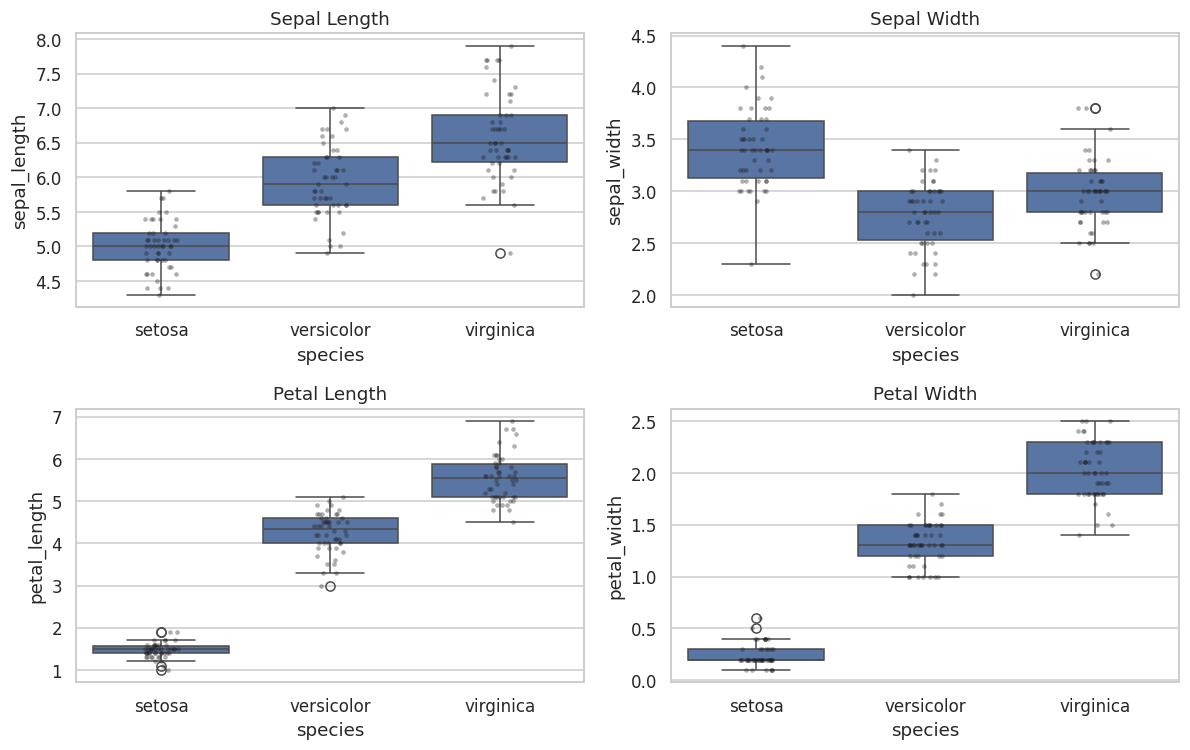

In [5]:
features = cols[:4]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df, x='species', y=col, ax=ax)
    sns.stripplot(data=df, x='species', y=col, ax=ax, color='k', alpha=.35, size=3)
    ax.set_title(col.replace('_', ' ').title())
plt.tight_layout()

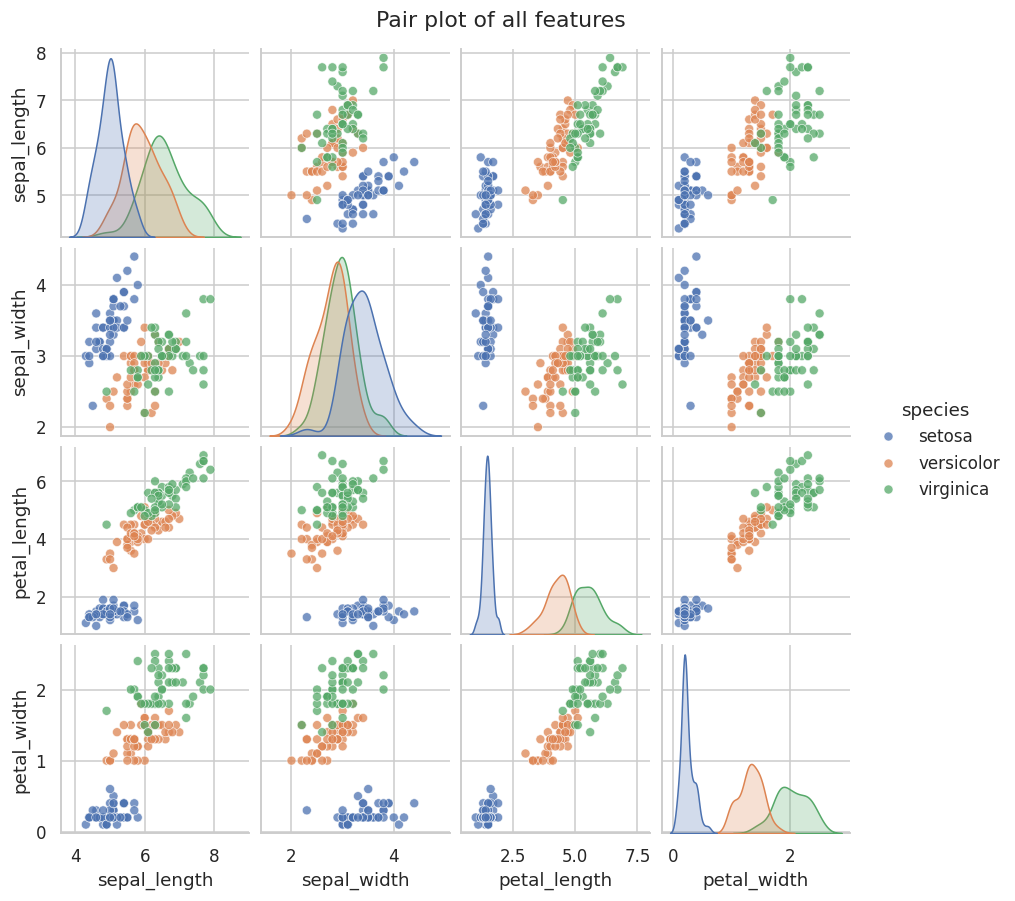

In [6]:
g = sns.pairplot(df, hue='species', corner=False, plot_kws={'alpha': .75, 's': 35}, height=2.0)
g.figure.suptitle('Pair plot of all features', y=1.02)

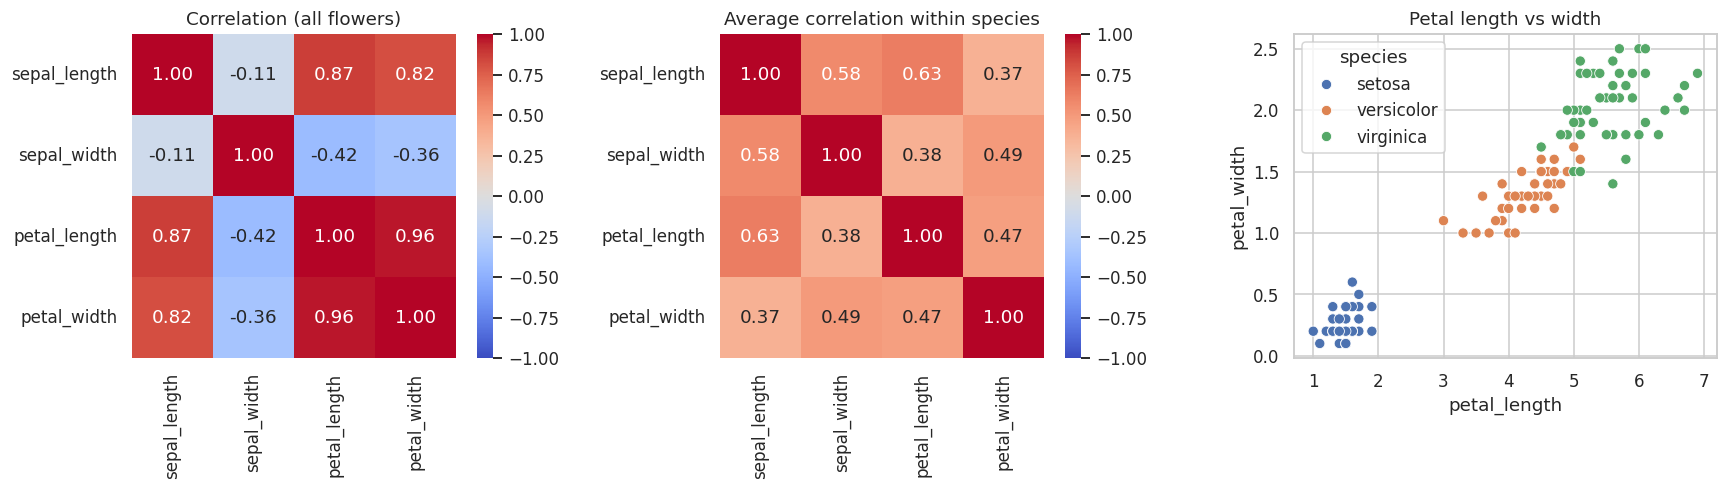

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
corr_all = df[features].corr()
sns.heatmap(corr_all, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title('Correlation (all flowers)')
within = df.groupby('species')[features].corr().groupby(level=1).mean().loc[features, features]
sns.heatmap(within, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title('Average correlation within species')
sns.scatterplot(data=df, x='petal_length', y='petal_width', hue='species', ax=axes[2], s=45)
axes[2].set_title('Petal length vs width')
plt.tight_layout()

**Observations**
- **Setosa** is completely separated from the other two species by its small petals - petal length and width alone identify it with no overlap.
- **Versicolor** and **virginica** overlap a little, mostly in sepal measurements; the petal features separate them much better.
- Petal length and petal width are very strongly correlated (about 0.96), so they carry largely the same information.

## 3. PCA: how much structure is there in 4 dimensions?

Explained variance ratio: [0.728 0.23  0.037 0.005]
First two components explain 95.8% of the variance

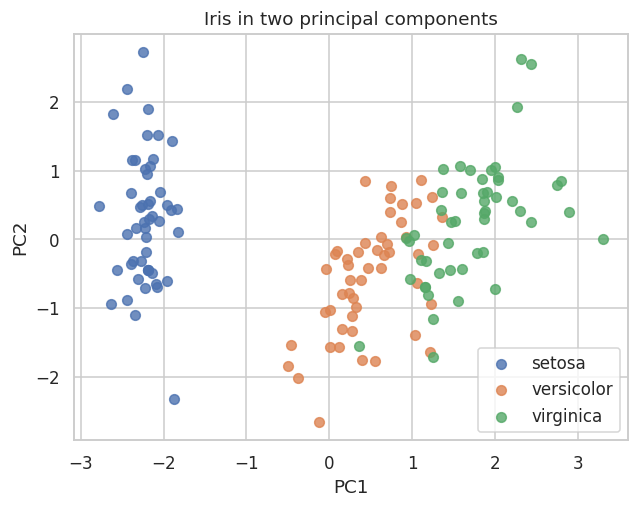

In [8]:
X = df[features].values
le = LabelEncoder()
y = le.fit_transform(df['species'])
pca = PCA().fit(StandardScaler().fit_transform(X))
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3))
print('First two components explain {:.1%} of the variance'.format(pca.explained_variance_ratio_[:2].sum()))

coords = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
plt.figure(figsize=(6.5, 4.8))
for k, name in enumerate(le.classes_):
    plt.scatter(coords[y == k, 0], coords[y == k, 1], label=name, alpha=.8, s=40)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Iris in two principal components'); plt.legend()

Two components keep most of the information and already show three clear clusters, so a simple classifier should work very well.

## 4. Model comparison
Each model sits in a pipeline with a scaler (important for KNN, SVM and logistic regression). Because the dataset is tiny, we use **5-fold stratified cross-validation repeated 10 times** (50 scores per model) for a stable comparison.

In [9]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)': SVC(),
    'Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB(),
    'LDA': LinearDiscriminantAnalysis(),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
scores = {name: cross_val_score(Pipeline([('scale', StandardScaler()), ('clf', m)]), X, y, cv=cv, scoring='accuracy')
          for name, m in models.items()}
cv_table = pd.DataFrame({n: {'Mean accuracy': s.mean(), 'Std': s.std(), 'Min': s.min()} for n, s in scores.items()}).T
cv_table.sort_values('Mean accuracy', ascending=False).round(4)

                     Mean accuracy     Std     Min
LDA                         0.9793  0.0230  0.9000
SVM (RBF)                   0.9620  0.0333  0.8667
Naive Bayes                 0.9547  0.0345  0.8667
Logistic Regression         0.9533  0.0346  0.9000
KNN (k=5)                   0.9500  0.0285  0.9000
Random Forest               0.9500  0.0335  0.9000
Decision Tree               0.9380  0.0377  0.8667

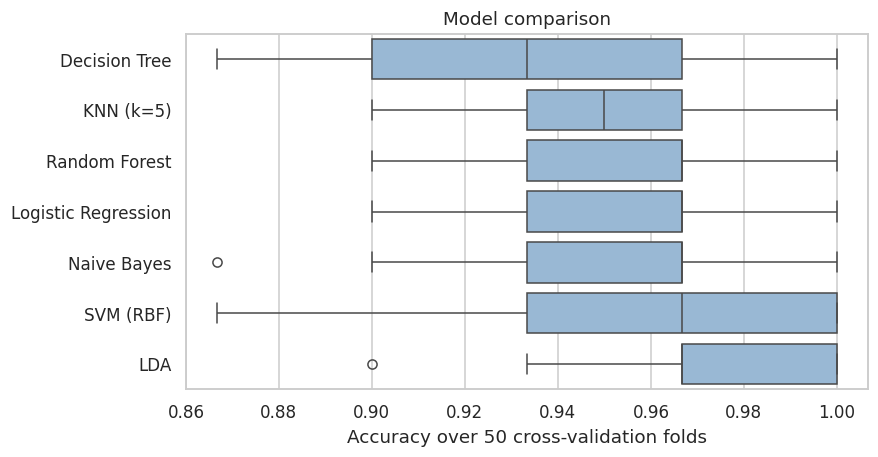

In [10]:
plt.figure(figsize=(8, 4.2))
order = cv_table.sort_values('Mean accuracy').index
sns.boxplot(data=pd.DataFrame(scores)[order], orient='h', color='#8FB8DE')
plt.xlabel('Accuracy over 50 cross-validation folds'); plt.title('Model comparison')

## 5. Hold-out test set and tuning
Keep 30% of the flowers (stratified) completely unseen. Tune KNN and SVM on the training part with grid search.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

grids = {
    'KNN': (KNeighborsClassifier(), {'clf__n_neighbors': list(range(1, 21)), 'clf__weights': ['uniform', 'distance']}),
    'SVM': (SVC(), {'clf__C': [0.1, 1, 3, 10, 30], 'clf__gamma': ['scale', 0.01, 0.03, 0.1, 0.3], 'clf__kernel': ['rbf', 'linear']}),
}
best = {}
for name, (clf, grid) in grids.items():
    gs = GridSearchCV(Pipeline([('scale', StandardScaler()), ('clf', clf)]), grid,
                      cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE), scoring='accuracy')
    gs.fit(X_train, y_train)
    best[name] = gs
    print(f'{name}: best CV accuracy {gs.best_score_:.4f} with', {k.replace('clf__', ''): v for k, v in gs.best_params_.items()})

Train: (105, 4)  Test: (45, 4)
KNN: best CV accuracy 0.9752 with {'n_neighbors': 9, 'weights': 'distance'}
SVM: best CV accuracy 0.9810 with {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}

In [12]:
final = {'Logistic Regression': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train),
         'Random Forest': Pipeline([('scale', StandardScaler()), ('clf', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]).fit(X_train, y_train),
         'Tuned KNN': best['KNN'].best_estimator_, 'Tuned SVM': best['SVM'].best_estimator_}
res = pd.Series({n: accuracy_score(y_test, m.predict(X_test)) for n, m in final.items()}, name='Test accuracy')
res.round(4).to_frame()

                     Test accuracy
Logistic Regression         0.9111
Random Forest               0.8889
Tuned KNN                   0.9333
Tuned SVM                   0.9111

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

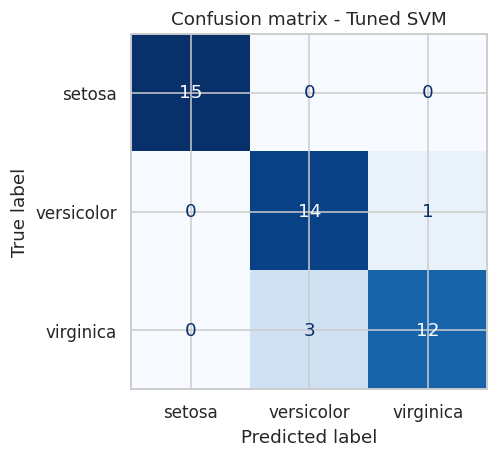

In [13]:
chosen_name = 'Tuned SVM'   # picked because it had the best cross-validated score in the grid search (0.981), not by looking at the test set
chosen = final[chosen_name]
pred = chosen.predict(X_test)
print(classification_report(y_test, pred, target_names=le.classes_))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=le.classes_, cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Confusion matrix - {chosen_name}')

The test set has only 45 flowers, so one flower is worth about 2.2 percentage points - differences between the top models on this split are not meaningful. The repeated cross-validation in section 4 is the fairer comparison. The selected SVM never confuses *setosa* with anything else; every error is between *versicolor* and *virginica*.

## 6. Decision boundaries and an interpretable tree

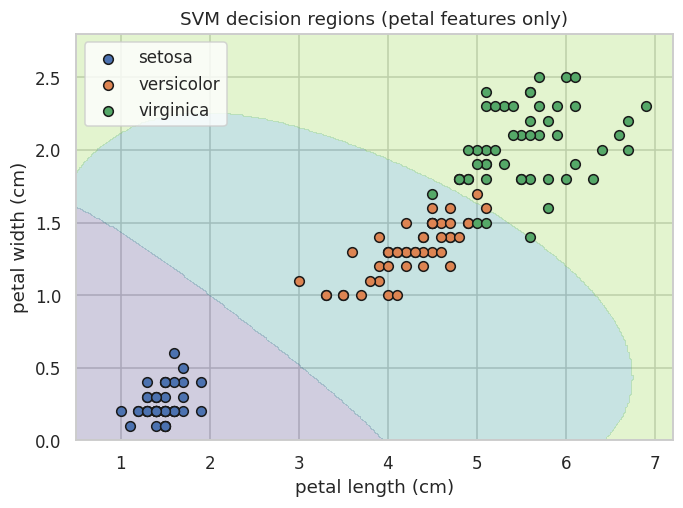

In [14]:
# Decision regions using only the two petal features
Xp = df[['petal_length', 'petal_width']].values
clf2 = Pipeline([('scale', StandardScaler()), ('clf', SVC(C=1, kernel='rbf'))]).fit(Xp, y)
xx, yy = np.meshgrid(np.linspace(0.5, 7.2, 300), np.linspace(0, 2.8, 300))
zz = clf2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(7, 4.8))
plt.contourf(xx, yy, zz, alpha=.25, cmap='viridis', levels=[-.5, .5, 1.5, 2.5])
for k, name in enumerate(le.classes_):
    plt.scatter(Xp[y == k, 0], Xp[y == k, 1], label=name, edgecolor='k', s=40)
plt.xlabel('petal length (cm)'); plt.ylabel('petal width (cm)'); plt.title('SVM decision regions (petal features only)'); plt.legend()

Tree test accuracy: 0.978

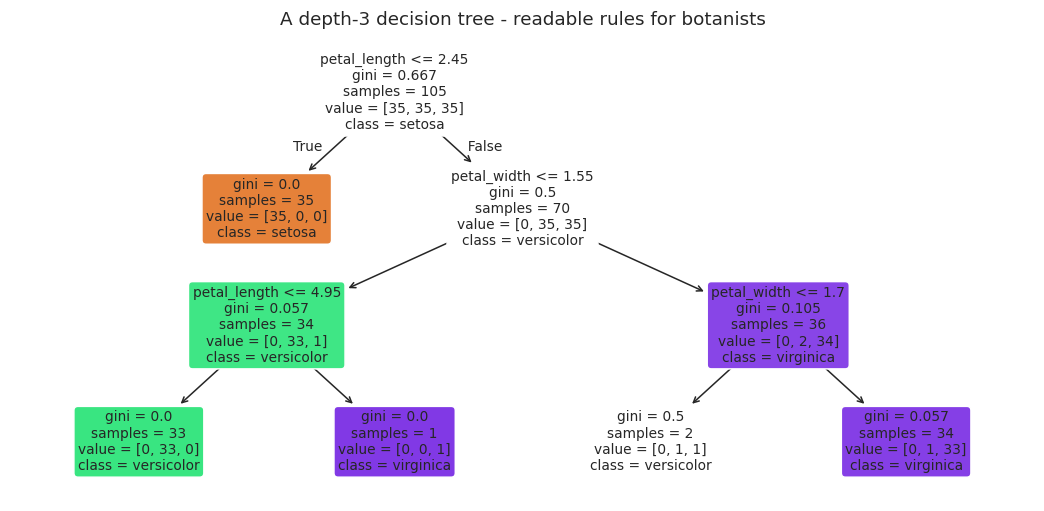

In [15]:
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(12, 5.5))
plot_tree(tree, feature_names=features, class_names=list(le.classes_), filled=True, rounded=True, fontsize=9)
plt.title('A depth-3 decision tree - readable rules for botanists')
print('Tree test accuracy: {:.3f}'.format(tree.score(X_test, y_test)))

petal_length    0.431
petal_width     0.427
sepal_length    0.115
sepal_width     0.027
dtype: float64

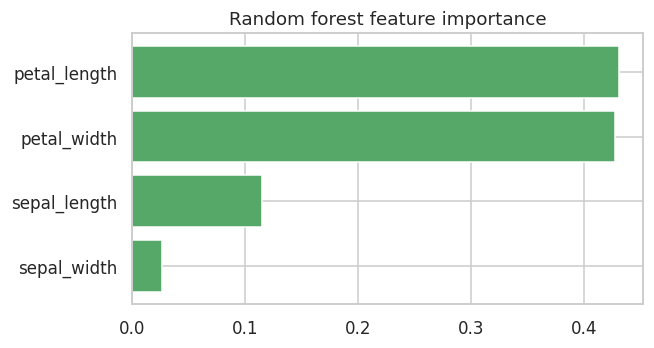

In [16]:
rf = final['Random Forest'].named_steps['clf']
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
plt.figure(figsize=(6, 3.2))
plt.barh(imp.index, imp.values, color='#55A868'); plt.title('Random forest feature importance')
imp.sort_values(ascending=False).round(3)

## 7. Save the model and predict new flowers

In [17]:
final_model = Pipeline([('scale', StandardScaler()), ('clf', SVC(**{k.replace('clf__', ''): v for k, v in best['SVM'].best_params_.items()}, probability=True, random_state=RANDOM_STATE))])
final_model.fit(X, y)           # refit on all 150 flowers
joblib.dump({'model': final_model, 'classes': list(le.classes_), 'features': features}, 'iris_model.joblib')
print('Saved iris_model.joblib')

def predict_species(sepal_length, sepal_width, petal_length, petal_width):
    sample = pd.DataFrame([[sepal_length, sepal_width, petal_length, petal_width]], columns=features).values
    proba = final_model.predict_proba(sample)[0]
    return le.classes_[proba.argmax()], dict(zip(le.classes_, proba.round(3)))

for flower in [(5.1, 3.5, 1.4, 0.2), (6.0, 2.9, 4.5, 1.5), (6.9, 3.1, 5.8, 2.1)]:
    print(flower, '->', predict_species(*flower))

Saved iris_model.joblib
(5.1, 3.5, 1.4, 0.2) -> ('setosa', {'setosa': np.float64(0.984), 'versicolor': np.float64(0.009), 'virginica': np.float64(0.007)})
(6.0, 2.9, 4.5, 1.5) -> ('versicolor', {'setosa': np.float64(0.007), 'versicolor': np.float64(0.933), 'virginica': np.float64(0.06)})
(6.9, 3.1, 5.8, 2.1) -> ('virginica', {'setosa': np.float64(0.007), 'versicolor': np.float64(0.002), 'virginica': np.float64(0.991)})

## 8. Conclusions
- Iris species are almost perfectly separable: **setosa** is trivial to identify, and **versicolor vs virginica** is the only real challenge.
- Petal length and petal width are the most informative features; sepal width adds the least.
- Seven very different classifiers land between **94% and 98%** accuracy in repeated cross-validation (LDA about 98%, SVM 96%, Naive Bayes, logistic regression, KNN and random forest about 95%, a depth-3 tree 94%), so the choice of model matters little. Simple, interpretable models are good enough.
- After tuning, the SVM reached about **98% cross-validated accuracy** on the training part and 91% on the 45 held-out flowers; a plain depth-3 tree scored 98% on that same split. Single splits of 45 flowers are noisy (one flower = 2.2 points), so report the cross-validated range rather than one number.
- `iris_model.joblib` contains the final pipeline and `predict_species(...)` shows how to classify a new flower.

**Limitations:** a tiny, clean, balanced dataset; real-world flower photos or measurements would be noisier and would need more data and more careful validation.